# Generalization Study — HOG + SVM

Investigate how training dataset size affects model
performance on unseen drivers.

In [1]:
import numpy as np
from pathlib import Path

# Load our previously extracted HOG features
feature_dir = Path("../data/processed/hog/driver_based")

X_train = np.load(feature_dir / "X_train.npy")
y_train = np.load(feature_dir / "y_train.npy")

X_val = np.load(feature_dir / "X_val.npy")
y_val = np.load(feature_dir / "y_val.npy")

print("Training:", X_train.shape)
print("Validation:", X_val.shape)

Training: (15732, 1764)
Validation: (3603, 1764)


## Step 2 — Create Training Subsets

Create reproducible training subsets containing 25%, 50%,
75%, and 100% of the original training data.

In [2]:
from sklearn.model_selection import train_test_split

# All training image indices
indices = np.arange(len(y_train))

# Select 75% of training images
idx_75, _ = train_test_split(
    indices,
    train_size=0.75,
    stratify=y_train,
    random_state=42
)

# Select 50% of original images from the 75% subset
idx_50, _ = train_test_split(
    idx_75,
    train_size=2/3,
    stratify=y_train[idx_75],
    random_state=42
)

# Select 25% of original images from the 50% subset
idx_25, _ = train_test_split(
    idx_50,
    train_size=0.5,
    stratify=y_train[idx_50],
    random_state=42
)

# Store subsets for experiments
subsets = {
    25: idx_25,
    50: idx_50,
    75: idx_75,
    100: indices
}

for percentage, idx in subsets.items():
    print(f"{percentage}%: {len(idx)} images")

25%: 3933 images
50%: 7866 images
75%: 11799 images
100%: 15732 images


## Step 3 — Train SVM with 25% of Training Data

Train and evaluate HOG + SVM using a smaller training dataset
to study how training size affects model performance.

In [3]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score
import time

# Select 25% of training data
X_25 = X_train[subsets[25]]
y_25 = y_train[subsets[25]]

# Create the same model as our baseline
model_25 = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(
        C=1.0,
        max_iter=10000,
        random_state=42
    ))
])

# Train the model and measure time
start = time.perf_counter()

model_25.fit(X_25, y_25)

training_time = time.perf_counter() - start

# Evaluate on the same validation dataset
y_pred_25 = model_25.predict(X_val)

accuracy_25 = accuracy_score(y_val, y_pred_25)
f1_25 = f1_score(y_val, y_pred_25, average="macro")

print(f"Training time: {training_time:.2f} seconds")
print(f"Validation accuracy: {accuracy_25:.2%}")
print(f"Macro-F1: {f1_25:.4f}")

Training time: 691.15 seconds
Validation accuracy: 44.55%
Macro-F1: 0.4356


## Step 4 — Save the 25% Experiment

Save the trained SVM and validation metrics for comparison.

In [4]:
import joblib
import json
from pathlib import Path

# Create folders
model_dir = Path("../models")
results_dir = Path("../results/hog_svm/generalization")

model_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

# Save trained model
joblib.dump(model_25, model_dir / "hog_svm_25.joblib")

# Save experiment results
result_25 = {
    "training_percentage": 25,
    "training_images": len(y_25),
    "accuracy": float(accuracy_25),
    "macro_f1": float(f1_25),
    "training_seconds": float(training_time)
}

with open(results_dir / "25_percent.json", "w") as f:
    json.dump(result_25, f, indent=4)

print("25% experiment saved successfully!")

25% experiment saved successfully!


## Step 5 — Train SVM with 50% of Training Data

Evaluate whether increasing training data improves generalization
to unseen drivers.

In [5]:
# Select 50% of training data
X_50 = X_train[subsets[50]]
y_50 = y_train[subsets[50]]

# Create the same SVM pipeline
model_50 = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(
        C=1.0,
        max_iter=10000,
        random_state=42
    ))
])

# Train and measure time
start = time.perf_counter()

model_50.fit(X_50, y_50)

training_time_50 = time.perf_counter() - start

# Evaluate on the unchanged validation set
y_pred_50 = model_50.predict(X_val)

accuracy_50 = accuracy_score(y_val, y_pred_50)
f1_50 = f1_score(y_val, y_pred_50, average="macro")

print(f"Training time: {training_time_50:.2f} seconds")
print(f"Validation accuracy: {accuracy_50:.2%}")
print(f"Macro-F1: {f1_50:.4f}")

Training time: 957.10 seconds
Validation accuracy: 42.13%
Macro-F1: 0.4064


In [6]:
# Save the trained model
joblib.dump(model_50, model_dir / "hog_svm_50.joblib")

# Save experiment metrics
result_50 = {
    "training_percentage": 50,
    "training_images": len(y_50),
    "accuracy": float(accuracy_50),
    "macro_f1": float(f1_50),
    "training_seconds": float(training_time_50)
}

with open(results_dir / "50_percent.json", "w") as f:
    json.dump(result_50, f, indent=4)

print("50% experiment saved!")

50% experiment saved!


## Step 7 — Train SVM with 75% of Training Data

Evaluate HOG + SVM using 75% of the training dataset
to investigate how dataset size affects generalization.

In [7]:
# Select 75% of training data
X_75 = X_train[subsets[75]]
y_75 = y_train[subsets[75]]

# Create the same SVM pipeline
model_75 = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", LinearSVC(
        C=1.0,
        max_iter=10000,
        random_state=42
    ))
])

# Train and measure time
start = time.perf_counter()

model_75.fit(X_75, y_75)

training_time_75 = time.perf_counter() - start

# Evaluate using the unchanged validation set
y_pred_75 = model_75.predict(X_val)

accuracy_75 = accuracy_score(y_val, y_pred_75)
f1_75 = f1_score(y_val, y_pred_75, average="macro")

print(f"Training time: {training_time_75:.2f} seconds")
print(f"Validation accuracy: {accuracy_75:.2%}")
print(f"Macro-F1: {f1_75:.4f}")

Training time: 1027.09 seconds
Validation accuracy: 43.10%
Macro-F1: 0.4164


In [8]:
# Save the trained model
joblib.dump(model_75, model_dir / "hog_svm_75.joblib")

# Record experiment results
result_75 = {
    "training_percentage": 75,
    "training_images": len(y_75),
    "accuracy": float(accuracy_75),
    "macro_f1": float(f1_75),
    "training_seconds": float(training_time_75)
}

# Save metrics as JSON
with open(results_dir / "75_percent.json", "w") as f:
    json.dump(result_75, f, indent=4)

print("75% experiment saved successfully!")

75% experiment saved successfully!


## Step 9 — Generalization Study Results

Visualize how training dataset size affects validation accuracy
and macro-F1.

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

# Combine results from all experiments
results = pd.DataFrame({
    "Training %": [25, 50, 75, 100],
    "Accuracy": [accuracy_25, accuracy_50, accuracy_75, 0.4252],
    "Macro-F1": [f1_25, f1_50, f1_75, 0.4180]
})

display(results)

,Training %,Accuracy,Macro-F1
0,25,0.445462,0.435565
1,50,0.421316,0.406384
2,75,0.431030,0.416446
3,100,0.425200,0.418000


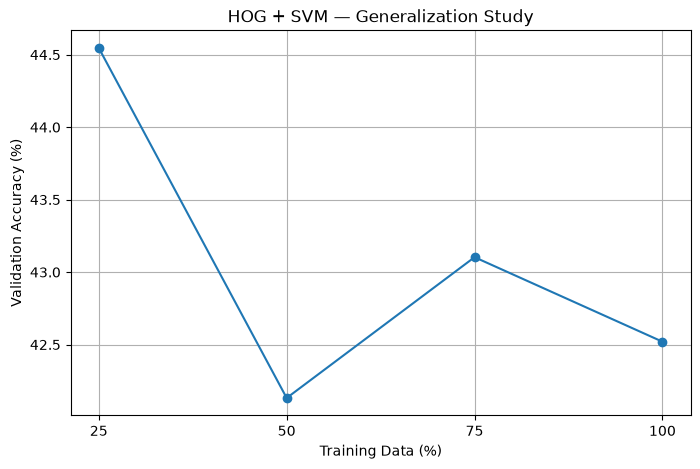

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(
    results["Training %"],
    results["Accuracy"] * 100,
    marker="o"
)

plt.xlabel("Training Data (%)")
plt.ylabel("Validation Accuracy (%)")
plt.title("HOG + SVM — Generalization Study")
plt.xticks([25, 50, 75, 100])
plt.grid(True)

plt.savefig("../results/figures/hog_svm_accuracy.png",
            dpi=300, bbox_inches="tight")

plt.show()


## Generalization Study — Results and Discussion

### Objective
Investigate how increasing the amount of training data affects HOG + SVM performance on previously unseen drivers.

### Methodology
We trained four Linear SVM classifiers using 25%, 50%, 75%, and 100% of the driver-based training dataset.

All experiments used:
- HOG features (1,764 per image)
- StandardScaler + LinearSVC (C=1.0)
- Random seed: 42
- The same validation set of 3,603 images from four unseen drivers

### Results

| Training Data | Accuracy | Macro-F1 |
|---|---|---|
| 25% (3,933) | **44.55%** | **0.4356** |
| 50% (7,866) | 42.13% | 0.4064 |
| 75% (11,799) | 43.10% | 0.4164 |
| 100% (15,732) | 42.52% | 0.4180 |

### Discussion

The model did not consistently improve as training data increased. Surprisingly, the 25% model achieved the highest validation accuracy (44.55%).

Possible explanations include:
1. HOG features may not capture enough information to distinguish complex driving activities.
2. The selected training subsets may contain different amounts of useful variation.
3. The SVM may struggle to generalize to previously unseen drivers.

However, these results come from a single random seed and validation split, so we cannot conclude that smaller training datasets are generally better.

### Conclusion

Increasing the amount of training data alone did not consistently improve HOG + SVM generalization. More experiments would be needed to determine whether performance has saturated.

Next, we will investigate whether CNN-based models can learn more informative visual features and improve performance on unseen drivers.
